<a href="https://colab.research.google.com/github/jyotidabass/-Research-Frontiers-in-Computer-Vision-Classification-Detection-Segmentation-and-Vision-Models/blob/main/Colab_Demo_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Research Frontiers in Computer Vision: Live Demo (Sections 6 and 7)
**How to use:** Runtime > Change runtime type > GPU (T4). Then Runtime > Run all. No uploads needed: photos are downloaded in Step 1.

Step 1: build the six images. Step 2: load the three models. Step 3: run them on every image. Step 4: evaluation metrics (outputs below are real and already saved).

In [1]:
!pip -q install transformers torch pillow matplotlib

## Step 1: Six images (clean, small, occluded, blurred, night_rain, cluttered)

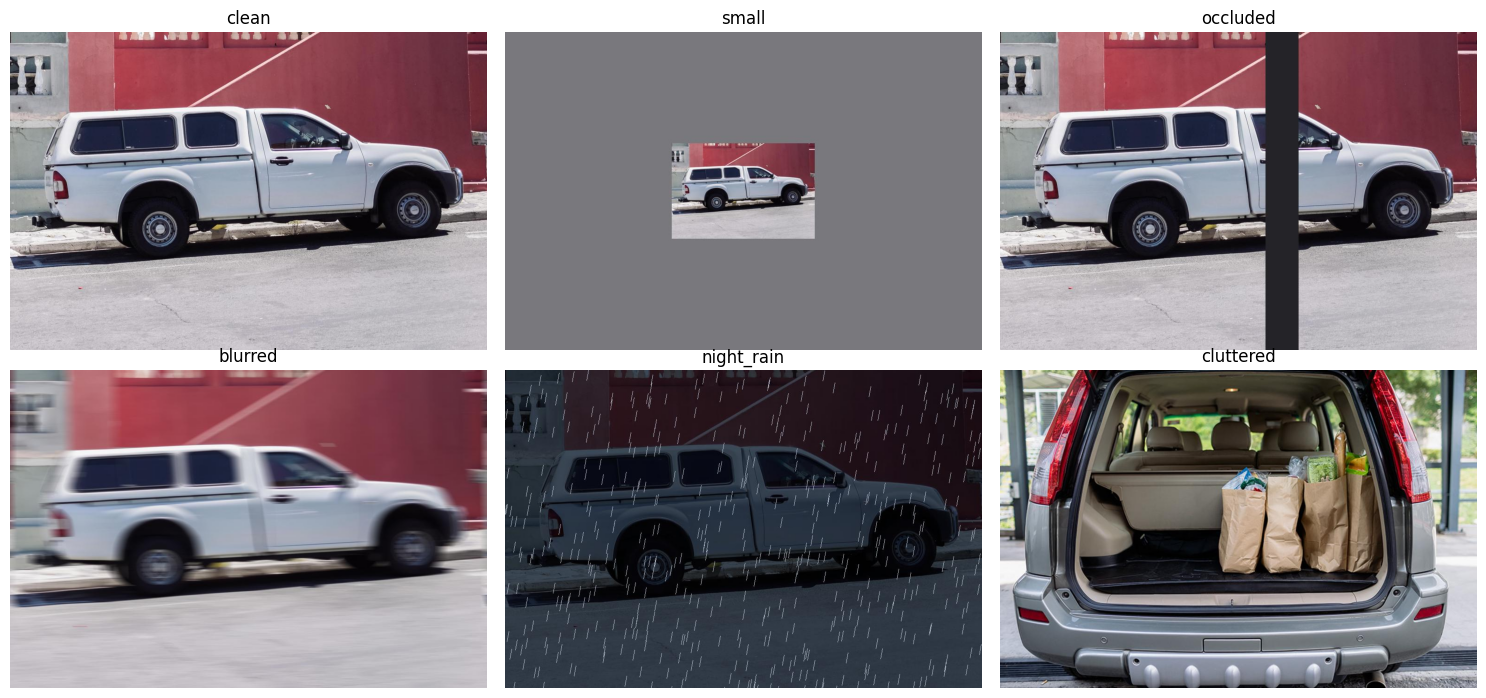

In [2]:
import os, urllib.request, numpy as np
from PIL import Image, ImageDraw, ImageEnhance
import matplotlib.pyplot as plt
os.makedirs("images", exist_ok=True)
U = "https://raw.githubusercontent.com/facebookresearch/segment-anything/main/notebooks/images/"
for f in ("truck.jpg", "groceries.jpg"):
    urllib.request.urlretrieve(U + f, "images/" + f)
base = Image.open("images/truck.jpg").convert("RGB").resize((1024, 683))
base.save("images/clean.jpg")
sm = base.resize((307, 205)); c = Image.new("RGB", (1024, 683), (120, 120, 125))
c.paste(sm, (358, 239)); c.save("images/small.jpg")
oc = base.copy(); ImageDraw.Draw(oc).rectangle([570, 0, 640, 683], fill=(35, 35, 40)); oc.save("images/occluded.jpg")
a = np.asarray(base).astype(np.float32)
Image.fromarray((sum(np.roll(a, s, axis=1) for s in range(-15, 16)) / 31).astype(np.uint8)).save("images/blurred.jpg")
nt = ImageEnhance.Brightness(base).enhance(0.35); r, g, b = nt.split()
nt = Image.merge("RGB", (r.point(lambda v: v*0.7), g.point(lambda v: v*0.85), b))
d = ImageDraw.Draw(nt); rng = np.random.default_rng(0)
for _ in range(500):
    x, y = rng.integers(0, 1024), rng.integers(0, 683); d.line([x, y, x-4, y+22], fill=(190, 200, 215), width=1)
nt.save("images/night_rain.jpg")
Image.open("images/groceries.jpg").convert("RGB").resize((1024, 683)).save("images/cluttered.jpg")
NAMES = ["clean", "small", "occluded", "blurred", "night_rain", "cluttered"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a_, n in zip(ax.ravel(), NAMES):
    a_.imshow(Image.open(f"images/{n}.jpg")); a_.set_title(n); a_.axis("off")
plt.tight_layout(); plt.show()

## Step 2: Load classifier (ViT), detector (DETR), promptable segmenter (SAM)

In [3]:
import torch, matplotlib.patches as pa
from transformers import pipeline, SamModel, SamProcessor
CLICK = {"clean": (540, 390), "small": (520, 356), "occluded": (400, 380),
         "blurred": (540, 390), "night_rain": (540, 390), "cluttered": (512, 340)}
dev = 0 if torch.cuda.is_available() else -1
clf = pipeline("image-classification", model="google/vit-base-patch16-224", device=dev)
det = pipeline("object-detection", model="facebook/detr-resnet-50", device=dev)
sam = SamModel.from_pretrained("facebook/sam-vit-base").to("cuda" if dev == 0 else "cpu")
proc = SamProcessor.from_pretrained("facebook/sam-vit-base")

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

## Step 3: Same images, three tasks

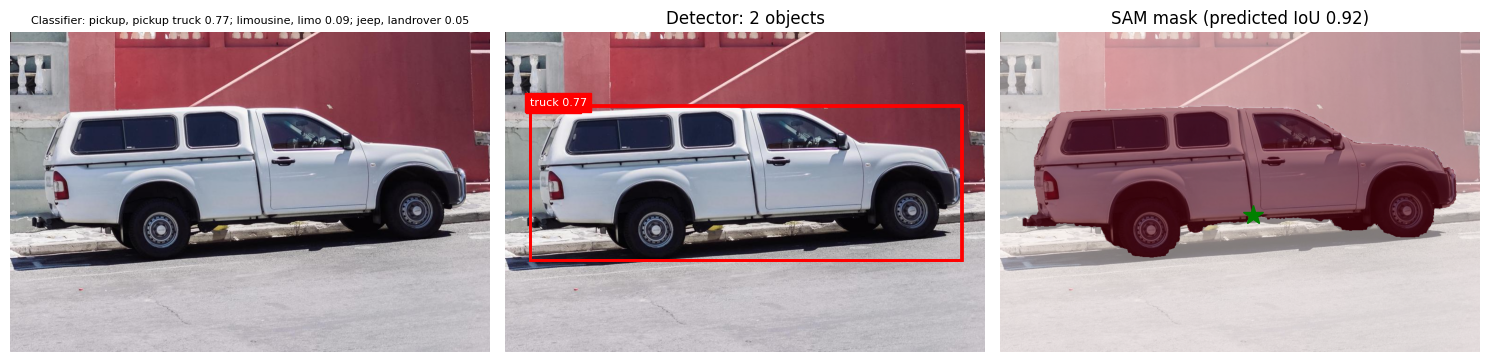

clean | top1: pickup, pickup truck | detections: [('car', 0.99), ('truck', 0.77)]


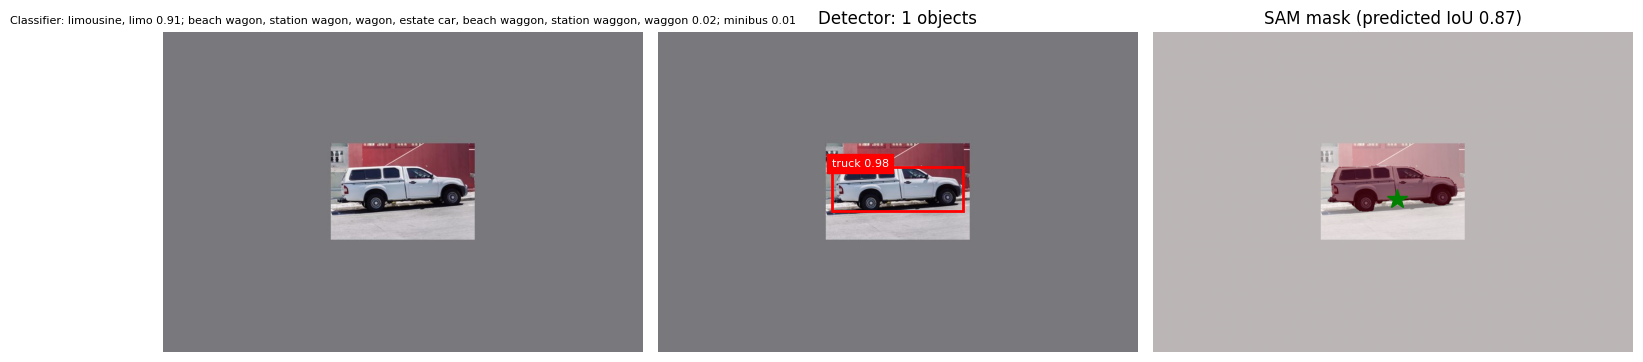

small | top1: limousine, limo | detections: [('truck', 0.98)]


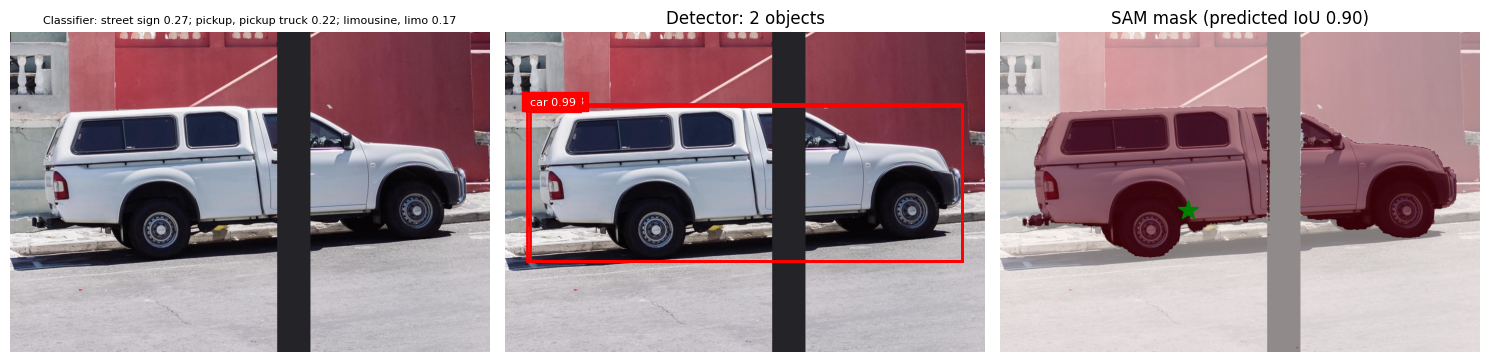

occluded | top1: street sign | detections: [('truck', 0.88), ('car', 0.99)]


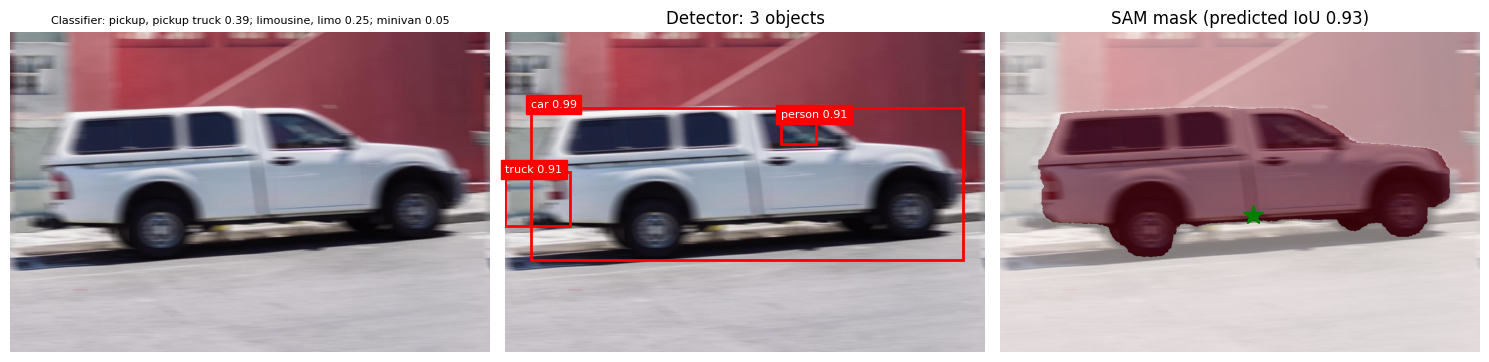

blurred | top1: pickup, pickup truck | detections: [('person', 0.91), ('truck', 0.91), ('car', 0.99)]


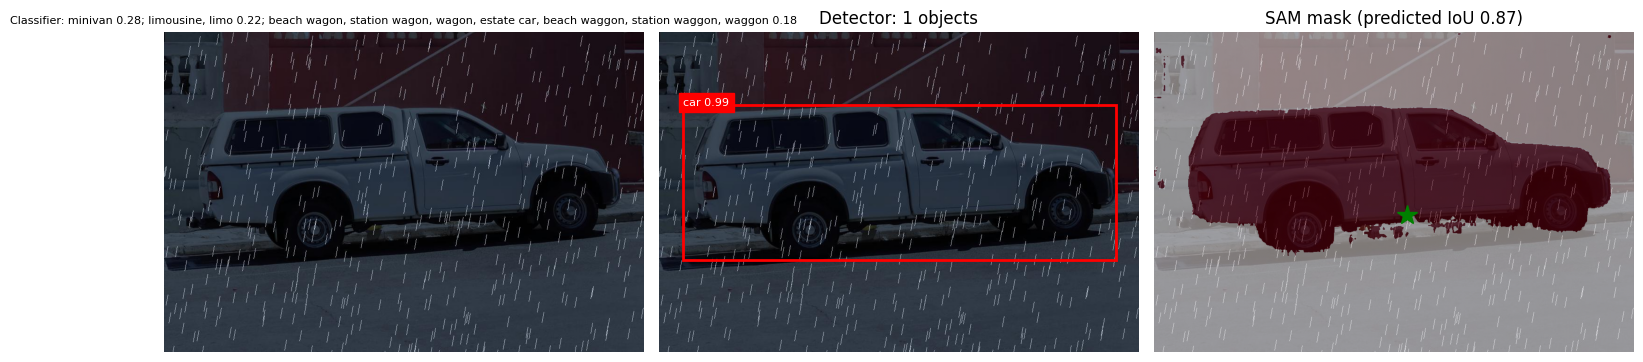

night_rain | top1: minivan | detections: [('car', 0.99)]


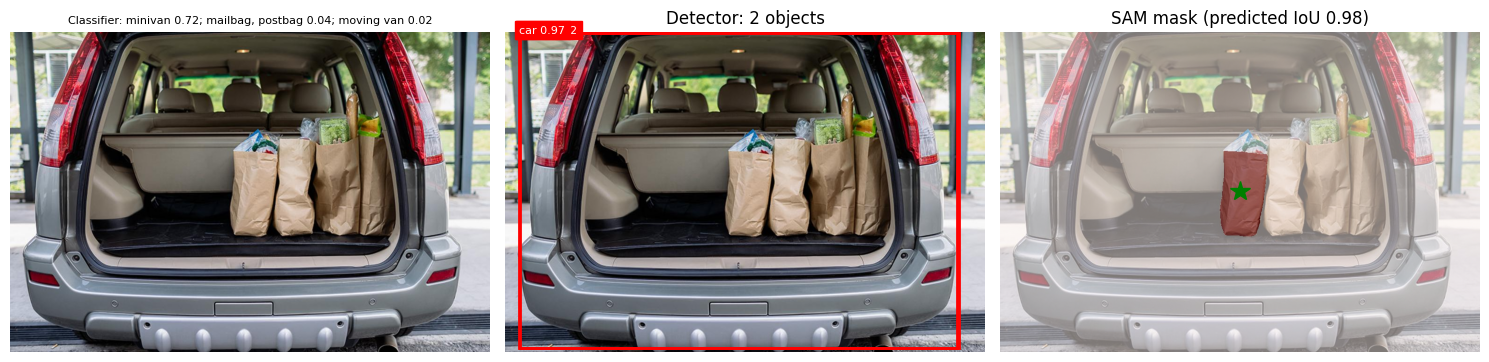

cluttered | top1: minivan | detections: [('truck', 0.82), ('car', 0.97)]


In [4]:
os.makedirs("outputs", exist_ok=True)
for n in NAMES:
    img = Image.open(f"images/{n}.jpg").convert("RGB")
    top3 = clf(img, top_k=3)
    boxes = det(img, threshold=0.7)
    inp = proc(img, input_points=[[list(CLICK[n])]], return_tensors="pt").to(sam.device)
    with torch.no_grad(): out = sam(**inp)
    masks = proc.image_processor.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu(),
                                                    inp["reshaped_input_sizes"].cpu())[0][0]
    best = int(out.iou_scores[0, 0].argmax())
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    ax[0].imshow(img); ax[0].set_title("Classifier: " + "; ".join(f"{t['label']} {t['score']:.2f}" for t in top3), fontsize=8)
    ax[1].imshow(img); ax[1].set_title(f"Detector: {len(boxes)} objects")
    for b in boxes:
        bx = b["box"]
        ax[1].add_patch(pa.Rectangle((bx["xmin"], bx["ymin"]), bx["xmax"]-bx["xmin"], bx["ymax"]-bx["ymin"], fill=False, color="red", lw=2))
        ax[1].text(bx["xmin"], bx["ymin"], f"{b['label']} {b['score']:.2f}", color="white", backgroundcolor="red", fontsize=8)
    ax[2].imshow(img); ax[2].imshow(masks[best].numpy(), alpha=0.5, cmap="Reds"); ax[2].plot(*CLICK[n], "g*", ms=15)
    ax[2].set_title(f"SAM mask (predicted IoU {out.iou_scores[0,0,best]:.2f})")
    [x.axis("off") for x in ax]; plt.tight_layout(); plt.savefig(f"outputs/{n}.png", dpi=110); plt.show()
    print(n, "| top1:", top3[0]["label"], "| detections:", [(b["label"], round(b["score"], 2)) for b in boxes])

## Step 4: Evaluation metrics (real outputs saved)

In [5]:
# ---# Pure Python/numpy - runs anywhere. Output is what appears on the slides.

In [6]:
# --- Classification: accuracy vs macro-F1 ---
y = [0]*6 + [1]*2 + [2] + [3]   # 3 = rare cow
p = [0]*6 + [1]*2 + [0] + [0]
acc = sum(a==b for a,b in zip(y,p)) / len(y)
f1s = []
for c in range(4):
    tp = sum(a==c and b==c for a,b in zip(y,p))
    fp = sum(a!=c and b==c for a,b in zip(y,p))
    fn = sum(a==c and b!=c for a,b in zip(y,p))
    f1s.append(2*tp/(2*tp+fp+fn) if tp else 0.0)
print("accuracy:", acc)
print("per-class F1:", [round(f,2) for f in f1s])
print("macro-F1:", round(sum(f1s)/4,2))

accuracy: 0.8
per-class F1: [0.86, 1.0, 0.0, 0.0]
macro-F1: 0.46


In [7]:
# --- Detection: IoU at several thresholds ---
import numpy as np
def iou(a, b):  # boxes [x1,y1,x2,y2]
    x1,y1 = max(a[0],b[0]), max(a[1],b[1])
    x2,y2 = min(a[2],b[2]), min(a[3],b[3])
    inter = max(0,x2-x1) * max(0,y2-y1)
    ua = ((a[2]-a[0])*(a[3]-a[1])
          + (b[2]-b[0])*(b[3]-b[1]) - inter)
    return inter / ua
gt = [[100,100,200,200], [300,120,380,200],
      [50,300,120,360], [400,300,430,330]]
pred = [[105,102,205,204], [310,130,392,214],
        [62,312,134,372], [415,315,447,349]]
ious = [iou(g,p) for g,p in zip(gt,pred)]
for t in (0.5,0.75,0.9):
    n = sum(i >= t for i in ious)
    print(f"IoU>={t}: {n}/4 correct")
print("IoUs:", [round(i,2) for i in ious])

IoU>=0.5: 2/4 correct
IoU>=0.75: 1/4 correct
IoU>=0.9: 0/4 correct
IoUs: [0.85, 0.58, 0.49, 0.13]


In [8]:
# --- Segmentation: pixel accuracy vs IoU vs Dice ---
import numpy as np
gt = np.zeros((100,100), bool)
gt[40:60, 40:60] = True        # small object
pr = np.zeros((100,100), bool)
pr[20:40, 20:40] = True        # mask misses it
inter = (gt & pr).sum()
union = (gt | pr).sum()
print("pixel acc:", round((gt==pr).mean(),3))
print("IoU      :", round(inter/union,3))
print("Dice     :", round(2*inter/(gt.sum()+pr.sum()),3))

pixel acc: 0.92
IoU      : 0.0
Dice     : 0.0
